# Tugas Kelompok Machine Learning (Kelompok 6)
Random Forest (begging algorithm) + Association Rule

Dataset yang digunakan: https://archive.ics.uci.edu/dataset/186/wine+quality

# import dataset

In [2]:
import io
import zipfile
import urllib.request

import pandas as pd

pd.set_option('display.max_columns', None)

## Unduh dan Baca Dataset

In [3]:
URL = 'https://archive.ics.uci.edu/static/public/186/wine+quality.zip'

req = urllib.request.Request(URL, headers={'User-Agent': 'Mozilla/5.0'})
with urllib.request.urlopen(req) as resp:
    zf = zipfile.ZipFile(io.BytesIO(resp.read()))

print('Isi zip:', zf.namelist())

red = pd.read_csv(zf.open('winequality-red.csv'), sep=';')
white = pd.read_csv(zf.open('winequality-white.csv'), sep=';')

print('Red   :', red.shape)
print('White :', white.shape)

Isi zip: ['winequality-red.csv', 'winequality-white.csv', 'winequality.names']
Red   : (1599, 12)
White : (4898, 12)


## Gabungkan red dan white

In [4]:
red['wine_type'] = 'red'
white['wine_type'] = 'white'

df = pd.concat([red, white], ignore_index=True)
print('Gabungan:', df.shape)
df.head()

Gabungan: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [6]:
df.info()
print('\nMissing value per kolom:')
print(df.isna().sum())
print('\nBaris duplikat:', df.duplicated().sum())
print('\nDistribusi quality:')
print(df['quality'].value_counts().sort_index())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  wine_type             6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB

Missing value per kolom:
fixed acidity           0
volatile ac

# Pemeriksaan dan pembersihan data


In [9]:
df.info()
print('\nMissing value per kolom:')
print(df.isna().sum())
print('\nBaris duplikat:', df.duplicated().sum())
print('\nDistribusi quality:')
print(df['quality'].value_counts().sort_index())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  wine_type             6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB

Missing value per kolom:
fixed acidity           0
volatile ac

## Validasi nama kolom dan tipe data

In [10]:
FEATURES = [
    'fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
    'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
    'pH', 'sulphates', 'alcohol',
]

df.columns = [c.strip().strip('"') for c in df.columns]

for col in FEATURES:
    df[col] = pd.to_numeric(df[col], errors='raise')
df['quality'] = pd.to_numeric(df['quality'], errors='raise').astype(int)

print(df.dtypes)

fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
wine_type                object
dtype: object


## Pemeriksaan rentang nilai

In [11]:
print('Jumlah nilai negatif per fitur:')
print((df[FEATURES] < 0).sum())
print('\nRentang quality:', df['quality'].min(), '-', df['quality'].max())

df[FEATURES + ['quality']].describe().T

Jumlah nilai negatif per fitur:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
dtype: int64

Rentang quality: 3 - 9


,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000
volatile acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000
citric acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000
residual sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100
free sulfur dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000
total sulfur dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.00000


## Pemeriksaan duplikat

In [12]:
n_dup = df.duplicated().sum()
print(f'Total baris duplikat: {n_dup:,} ({n_dup / len(df) * 100:.2f}%)\n')

dup_summary = pd.DataFrame({
    'total_baris': df['wine_type'].value_counts(),
    'duplikat': df[df.duplicated()]['wine_type'].value_counts(),
}).fillna(0).astype(int)
dup_summary['persen_duplikat'] = (dup_summary['duplikat'] / dup_summary['total_baris'] * 100).round(2)
display(dup_summary)

# Contoh baris yang terduplikasi
df[df.duplicated(keep=False)].sort_values(FEATURES).head(6)

Total baris duplikat: 1,177 (18.12%)



,total_baris,duplikat,persen_duplikat
wine_type,,,
white,4898,937,19.13
red,1599,240,15.01


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
6270,4.9,0.335,0.14,1.3,0.036,69.0,168.0,0.99212,3.47,0.46,10.466667,5,white
6271,4.9,0.335,0.14,1.3,0.036,69.0,168.0,0.99212,3.47,0.46,10.466667,5,white
5540,4.9,0.345,0.34,1.0,0.068,32.0,143.0,0.99138,3.24,0.40,10.100000,5,white
5549,4.9,0.345,0.34,1.0,0.068,32.0,143.0,0.99138,3.24,0.40,10.100000,5,white
4589,5.0,0.270,0.32,4.5,0.032,58.0,178.0,0.98956,3.45,0.31,12.600000,7,white
4606,5.0,0.270,0.32,4.5,0.032,58.0,178.0,0.98956,3.45,0.31,12.600000,7,white


## Pembersihan: hapus duplikat

In [13]:
df_clean = df.drop_duplicates().reset_index(drop=True)

print(f'Sebelum : {len(df):,} baris')
print(f'Sesudah : {len(df_clean):,} baris')
print(f'Dibuang : {len(df) - len(df_clean):,} baris')

Sebelum : 6,497 baris
Sesudah : 5,320 baris
Dibuang : 1,177 baris


## Pemeriksaan setelah pembersihan

In [15]:
assert df_clean.duplicated().sum() == 0, 'Masih ada duplikat'
assert df_clean.isna().sum().sum() == 0, 'Masih ada missing value'

print('Ukuran data bersih:', df_clean.shape)
print('\nJumlah per jenis wine:')
print(df_clean['wine_type'].value_counts())
print('\nDistribusi quality:')
print(df_clean['quality'].value_counts().sort_index())

Ukuran data bersih: (5320, 13)

Jumlah per jenis wine:
wine_type
white    3961
red      1359
Name: count, dtype: int64

Distribusi quality:
quality
3      30
4     206
5    1752
6    2323
7     856
8     148
9       5
Name: count, dtype: int64


# Persiapan data


## Import library dan parameter

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, matthews_corrcoef,
    roc_auc_score, average_precision_score,
    roc_curve, confusion_matrix, classification_report,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate, train_test_split

SEED = 42
TEST_SIZE = 0.20
HIGH_QUALITY_THRESHOLD = 7
PERMUTATION_REPEATS = 10

SCOPE_COLORS = {'Combined': '#6b21a8', 'Red': '#b91c1c', 'White': '#d97706'}

## Membuat target biner

In [17]:
df_model = df_clean.copy()
df_model['high_quality'] = (df_model['quality'] >= HIGH_QUALITY_THRESHOLD).astype(int)
df_model['wine_type_code'] = (df_model['wine_type'] == 'white').astype(int)   # 0 = red, 1 = white

n_pos = df_model['high_quality'].sum()
print(f'Kelas premium (quality >= {HIGH_QUALITY_THRESHOLD}): {n_pos:,} dari {len(df_model):,} ({n_pos / len(df_model) * 100:.2f}%)\n')

df_model.groupby('wine_type')['high_quality'].agg(['count', 'sum', 'mean']).rename(
    columns={'count': 'jumlah', 'sum': 'premium', 'mean': 'proporsi'}
)

Kelas premium (quality >= 7): 1,009 dari 5,320 (18.97%)



,jumlah,premium,proporsi
wine_type,,,
red,1359,184,0.135394
white,3961,825,0.208281


## Pembagian scope dan data latih/uji

In [18]:
scope_data = {
    'Combined': (df_model, FEATURES + ['wine_type_code']),
    'Red': (df_model[df_model['wine_type'] == 'red'].reset_index(drop=True), FEATURES),
    'White': (df_model[df_model['wine_type'] == 'white'].reset_index(drop=True), FEATURES),
}

splits = {}
for scope, (d, feats) in scope_data.items():
    X_train, X_test, y_train, y_test = train_test_split(
        d[feats], d['high_quality'], test_size=TEST_SIZE, random_state=SEED, stratify=d['high_quality']
    )
    splits[scope] = {'X_train': X_train, 'X_test': X_test, 'y_train': y_train, 'y_test': y_test}
    print(f'{scope:9s} | latih: {len(X_train):>5,} (premium {y_train.mean() * 100:5.2f}%) '
          f'| uji: {len(X_test):>5,} (premium {y_test.mean() * 100:5.2f}%) | fitur: {len(feats)}')

Combined  | latih: 4,256 (premium 18.96%) | uji: 1,064 (premium 18.98%) | fitur: 12
Red       | latih: 1,087 (premium 13.52%) | uji:   272 (premium 13.60%) | fitur: 11
White     | latih: 3,168 (premium 20.83%) | uji:   793 (premium 20.81%) | fitur: 11


# Pelatihan model

## Tiga varian Random Forest

1.   **M1 (Baseline)**: 300 tree, parameter default, cutoff probabilitas 0,50.
2.   **M2 (Cost-Sensitive)**: sama seperti M1, hanya ditambah class_weight='balanced_subsample' untuk menangani ketidakseimbangan kelas tanpa membuat data sintetis. Karena hanya satu hal yang berbeda, selisih M1 dan M2 bisa dikaitkan ke penanganan imbalance.
3. **M3 (Threshold-Optimized)**: model M2 dengan cutoff yang dicari lewat 5-fold out-of-fold pada data latih (memaksimalkan F1 kelas premium).


In [19]:
def optimize_threshold_oof(estimator, X_train, y_train, seed=SEED):
    '''Cari cutoff terbaik (F1 kelas premium) dari prediksi out-of-fold pada data latih.'''
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    oof_proba = cross_val_predict(clone(estimator), X_train, y_train, cv=cv, method='predict_proba')[:, 1]

    candidates = np.round(np.arange(0.30, 0.66, 0.01), 2)
    scores = [f1_score(y_train, (oof_proba >= t).astype(int), zero_division=0) for t in candidates]
    # F1 tertinggi menang; jika sama, pilih cutoff yang paling dekat dengan 0,50
    best = max(range(len(candidates)), key=lambda i: (round(scores[i], 12), -abs(candidates[i] - 0.5)))
    return float(candidates[best]), float(scores[best])

In [21]:
models = {}
thresholds = {}

for scope, sp in splits.items():
    m1 = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)
    m2 = RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample', random_state=SEED, n_jobs=-1)
    m1.fit(sp['X_train'], sp['y_train'])
    m2.fit(sp['X_train'], sp['y_train'])

    thr, oof_f1 = optimize_threshold_oof(m2, sp['X_train'], sp['y_train'])
    models[scope] = {'M1_Baseline': m1, 'M2_CostSensitive': m2}
    thresholds[scope] = thr
    print(f'{scope:9s} | cutoff M3 = {thr:.2f} (F1 out-of-fold = {oof_f1:.4f})')

Combined  | cutoff M3 = 0.33 (F1 out-of-fold = 0.5648)
Red       | cutoff M3 = 0.31 (F1 out-of-fold = 0.4803)
White     | cutoff M3 = 0.30 (F1 out-of-fold = 0.5891)


# Evaluasi model

## Metrik pada data uji

Precision, recall, F1, dan specificity dihitung untuk kelas Premium. ROC-AUC dan PR-AUC tidak bergantung pada cutoff, sehingga nilainya sama untuk M2 dan M3. PR-AUC lebih peka terhadap kelas minoritas daripada ROC-AUC.

In [22]:
MODEL_NAMES = ['M1_Baseline', 'M2_CostSensitive', 'M3_ThresholdOpt']

def get_proba(scope):
    X_test = splits[scope]['X_test']
    p1 = models[scope]['M1_Baseline'].predict_proba(X_test)[:, 1]
    p2 = models[scope]['M2_CostSensitive'].predict_proba(X_test)[:, 1]
    return {
        'M1_Baseline': (p1, 0.50),
        'M2_CostSensitive': (p2, 0.50),
        'M3_ThresholdOpt': (p2, thresholds[scope]),   # probabilitas M2, cutoff berbeda
    }

def compute_metrics(y_true, proba, cut):
    pred = (proba >= cut).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        'cutoff': cut,
        'accuracy': accuracy_score(y_true, pred),
        'balanced_acc': balanced_accuracy_score(y_true, pred),
        'precision': precision_score(y_true, pred, zero_division=0),
        'recall': recall_score(y_true, pred, zero_division=0),
        'specificity': tn / (tn + fp),
        'f1': f1_score(y_true, pred, zero_division=0),
        'f1_macro': f1_score(y_true, pred, average='macro', zero_division=0),
        'mcc': matthews_corrcoef(y_true, pred),
        'roc_auc': roc_auc_score(y_true, proba),
        'pr_auc': average_precision_score(y_true, proba),
    }

test_proba = {}
rows = []
for scope in splits:
    test_proba[scope] = get_proba(scope)
    for m_name, (proba, cut) in test_proba[scope].items():
        rows.append({'scope': scope, 'model': m_name, **compute_metrics(splits[scope]['y_test'], proba, cut)})

df_metrics = pd.DataFrame(rows)
df_metrics.set_index(['scope', 'model']).round(4)

cutoff  accuracy  balanced_acc  precision  recall  \
scope    model                                                                 
Combined M1_Baseline         0.50    0.8449        0.6579     0.6729  0.3564   
         M2_CostSensitive    0.50    0.8421        0.6391     0.6848  0.3119   
         M3_ThresholdOpt     0.33    0.8430        0.7629     0.5792  0.6337   
Red      M1_Baseline         0.50    0.8934        0.6650     0.7222  0.3514   
         M2_CostSensitive    0.50    0.8860        0.6380     0.6875  0.2973   
         M3_ThresholdOpt     0.31    0.8640        0.7163     0.5000  0.5135   
White    M1_Baseline         0.50    0.8348        0.6656     0.6889  0.3758   
         M2_CostSensitive    0.50    0.8260        0.6511     0.6517  0.3515   
         M3_ThresholdOpt     0.30    0.8121        0.7764     0.5364  0.7152   

                           specificity      f1  f1_macro     mcc  roc_auc  \
scope    model                                                              
Combined M1_Baseline            0.9594  0.4660    0.6877  0.4118   0.8709   
         M2_CostSensitive       0.9664  0.4286    0.6685  0.3883   0.8770   
         M3_ThresholdOpt        0.8921  0.6052    0.7536  0.5083   0.8770   
Red      M1_Baseline            0.9787  0.4727    0.7067  0.4552   0.8743   
         M2_CostSensitive       0.9787  0.4151    0.6760  0.4022   0.8761   
         M3_ThresholdOpt        0.9191  0.5067    0.7139  0.4278   0.8761   
White    M1_Baseline            0.9554  0.4863    0.6939  0.4238   0.8526   
         M2_CostSensitive       0.9506  0.4567    0.6765  0.3886   0.8595   
         M3_ThresholdOpt        0.8376  0.6130    0.7445  0.5011   0.8595   

                           pr_auc  
scope    model                     
Combined M1_Baseline       0.6139  
         M2_CostSensitive  0.6295  
         M3_ThresholdOpt   0.6295  
Red      M1_Baseline       0.5969  
         M2_CostSensitive  0.5765  
         M3_ThresholdOpt   0.5765  
White    M1_Baseline       0.6258  
         M2_CostSensitive  0.6283  
         M3_ThresholdOpt   0.6283

## Confusion matrix dan classification report
Confusion matrix disimpan untuk semua model dan dipakai di bagian Visualisasi. Classification report ditampilkan untuk model akhir (M3)

In [23]:
conf_mats = {}
for scope in splits:
    y_test = splits[scope]['y_test']
    for m_name, (proba, cut) in test_proba[scope].items():
        conf_mats[(scope, m_name)] = confusion_matrix(y_test, (proba >= cut).astype(int), labels=[0, 1])

for scope in splits:
    proba, cut = test_proba[scope]['M3_ThresholdOpt']
    print(f'===== {scope} Wine | M3 (cutoff {cut:.2f}) =====')
    print(classification_report(
        splits[scope]['y_test'], (proba >= cut).astype(int),
        target_names=['Reguler (0)', 'Premium (1)'], zero_division=0,
    ))

===== Combined Wine | M3 (cutoff 0.33) =====
              precision    recall  f1-score   support

 Reguler (0)       0.91      0.89      0.90       862
 Premium (1)       0.58      0.63      0.61       202

    accuracy                           0.84      1064
   macro avg       0.75      0.76      0.75      1064
weighted avg       0.85      0.84      0.85      1064

===== Red Wine | M3 (cutoff 0.31) =====
              precision    recall  f1-score   support

 Reguler (0)       0.92      0.92      0.92       235
 Premium (1)       0.50      0.51      0.51        37

    accuracy                           0.86       272
   macro avg       0.71      0.72      0.71       272
weighted avg       0.87      0.86      0.86       272

===== White Wine | M3 (cutoff 0.30) =====
              precision    recall  f1-score   support

 Reguler (0)       0.92      0.84      0.88       628
 Premium (1)       0.54      0.72      0.61       165

    accuracy                           0.81       793
 

## Stabilitas hasil: validasi silang 5-fold
Skor di data uji berasal dari satu kali pembagian saja. Validasi silang pada data latih (model M2, cutoff 0,50) menunjukkan seberapa stabil skornya antar fold.

In [24]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
for scope, sp in splits.items():
    res = cross_validate(
        clone(models[scope]['M2_CostSensitive']), sp['X_train'], sp['y_train'], cv=cv,
        scoring={'f1': 'f1', 'roc_auc': 'roc_auc', 'pr_auc': 'average_precision'},
    )
    cv_rows.append({
        'scope': scope,
        'F1 (rata-rata ± std)': f"{res['test_f1'].mean():.4f} ± {res['test_f1'].std():.4f}",
        'ROC-AUC (rata-rata ± std)': f"{res['test_roc_auc'].mean():.4f} ± {res['test_roc_auc'].std():.4f}",
        'PR-AUC (rata-rata ± std)': f"{res['test_pr_auc'].mean():.4f} ± {res['test_pr_auc'].std():.4f}",
    })

pd.DataFrame(cv_rows).set_index('scope')

,F1 (rata-rata ± std),ROC-AUC (rata-rata ± std),PR-AUC (rata-rata ± std)
scope,,,
Combined,0.4469 ± 0.0360,0.8496 ± 0.0117,0.5711 ± 0.0331
Red,0.3941 ± 0.0720,0.8717 ± 0.0325,0.5379 ± 0.0750
White,0.4297 ± 0.0360,0.8452 ± 0.0236,0.5912 ± 0.0402


# Feature importance

## Gini dan permutation importance
Dua ukuran dipakai karena masing-masing punya kelemahan. Gini importance dihitung dari data latih dan cenderung menguntungkan fitur yang berkorelasi atau bernilai kontinu. Permutation importance dihitung pada data uji sebagai penurunan ROC-AUC saat satu fitur diacak, sehingga lebih mencerminkan kontribusi nyata terhadap prediksi. Keduanya dihitung dari model M2.

In [26]:
imp_frames = []
for scope, sp in splits.items():
    m2 = models[scope]['M2_CostSensitive']
    perm = permutation_importance(
        m2, sp['X_test'], sp['y_test'], scoring='roc_auc',
        n_repeats=PERMUTATION_REPEATS, random_state=SEED, n_jobs=-1,
    )
    imp = pd.DataFrame({
        'scope': scope,
        'feature': sp['X_test'].columns,
        'gini_importance': m2.feature_importances_,
        'perm_importance_mean': perm.importances_mean,
        'perm_importance_std': perm.importances_std,
    }).sort_values('gini_importance', ascending=False).reset_index(drop=True)
    imp['rank_gini'] = imp.index + 1
    imp['rank_perm'] = imp['perm_importance_mean'].rank(ascending=False).astype(int)
    imp_frames.append(imp)

df_importance = pd.concat(imp_frames, ignore_index=True)

for scope in splits:
    print(f'\n=== Top 5 fitur: {scope} Wine ===')
    display(
        df_importance[df_importance['scope'] == scope].head(5)
        [['rank_gini', 'rank_perm', 'feature', 'gini_importance', 'perm_importance_mean', 'perm_importance_std']]
        .round(4).set_index('rank_gini')
    )


=== Top 5 fitur: Combined Wine ===


,rank_perm,feature,gini_importance,perm_importance_mean,perm_importance_std
rank_gini,,,,,
1,1,alcohol,0.2010,0.1381,0.0116
2,4,density,0.1200,0.0232,0.0053
3,3,chlorides,0.0886,0.0269,0.0065
4,2,volatile acidity,0.0872,0.0350,0.0061
5,9,total sulfur dioxide,0.0842,0.0141,0.0046



=== Top 5 fitur: Red Wine ===


,rank_perm,feature,gini_importance,perm_importance_mean,perm_importance_std
rank_gini,,,,,
1,1,alcohol,0.2248,0.1105,0.0259
2,2,sulphates,0.1408,0.0702,0.0180
3,3,volatile acidity,0.1071,0.0201,0.0075
4,5,citric acid,0.0987,0.0066,0.0082
5,7,total sulfur dioxide,0.0774,0.0022,0.0078



=== Top 5 fitur: White Wine ===


,rank_perm,feature,gini_importance,perm_importance_mean,perm_importance_std
rank_gini,,,,,
1,1,alcohol,0.1888,0.1231,0.0118
2,4,density,0.1306,0.0211,0.0071
3,7,chlorides,0.0924,0.0151,0.0045
4,6,total sulfur dioxide,0.0870,0.0153,0.0037
5,3,volatile acidity,0.0786,0.0238,0.0060


# Visualisasi


## Feature importance

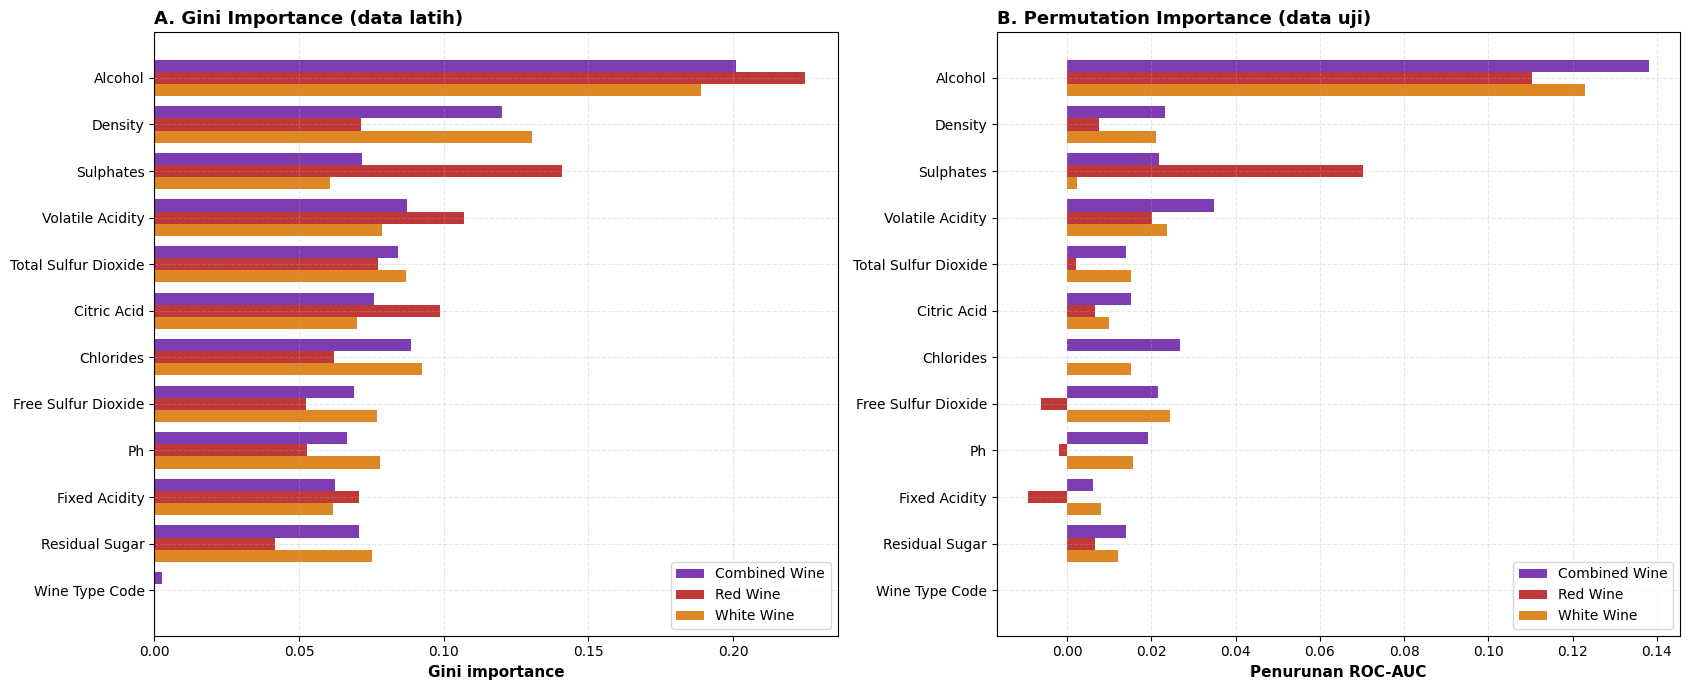

In [27]:
scopes_list = list(splits.keys())

def grouped_barh(ax, pivot, title, xlabel):
    y_pos = np.arange(len(pivot))
    bar_h = 0.26
    for i, s in enumerate(scopes_list):
        ax.barh(y_pos + (i - 1) * bar_h, pivot[s], height=bar_h, label=f'{s} Wine', color=SCOPE_COLORS[s], alpha=0.88)
    ax.set_yticks(y_pos)
    ax.set_yticklabels([f.replace('_', ' ').title() for f in pivot.index], fontsize=10)
    ax.invert_yaxis()
    ax.set_xlabel(xlabel, fontsize=11, fontweight='bold')
    ax.set_title(title, fontsize=13, fontweight='bold', loc='left')
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.legend(loc='lower right', fontsize=10)

gini = df_importance.pivot(index='feature', columns='scope', values='gini_importance')[scopes_list].fillna(0)
perm = df_importance.pivot(index='feature', columns='scope', values='perm_importance_mean')[scopes_list].fillna(0)
order = gini.mean(axis=1).sort_values(ascending=False).index
gini, perm = gini.loc[order], perm.loc[order]

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
grouped_barh(axes[0], gini, 'A. Gini Importance (data latih)', 'Gini importance')
grouped_barh(axes[1], perm, 'B. Permutation Importance (data uji)', 'Penurunan ROC-AUC')
plt.tight_layout()
plt.savefig('wine_rf_feature_importance.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

## Kurva ROC
Kurva ROC M2 dan M3 identik karena memakai probabilitas yang sama. M3 hanya berbeda pada titik cutoff yang dipilih.

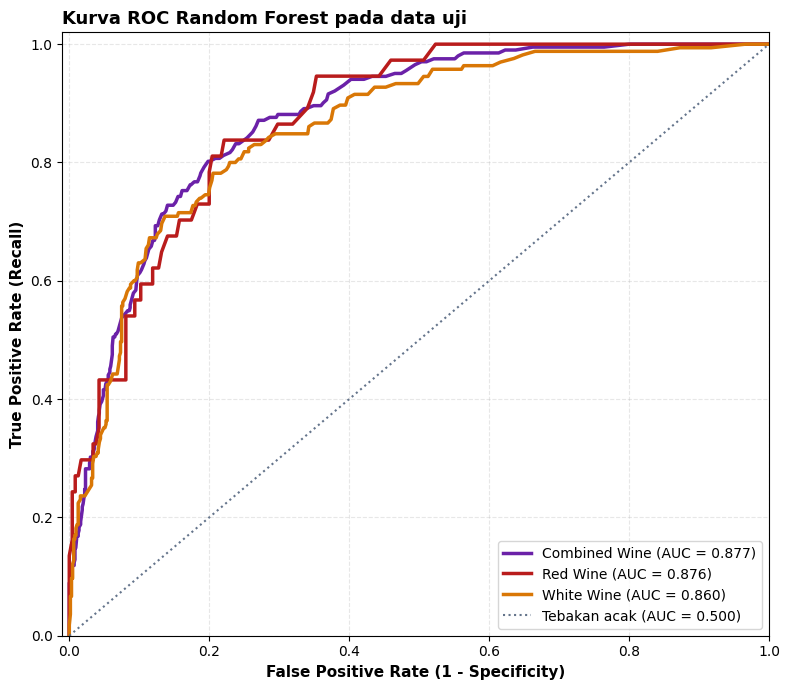

In [28]:
fig, ax = plt.subplots(figsize=(8, 7))
for s in scopes_list:
    y_test = splits[s]['y_test']
    proba = test_proba[s]['M2_CostSensitive'][0]
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, linewidth=2.5, color=SCOPE_COLORS[s],
            label=f'{s} Wine (AUC = {roc_auc_score(y_test, proba):.3f})')
ax.plot([0, 1], [0, 1], linestyle=':', color='#64748b', linewidth=1.5, label='Tebakan acak (AUC = 0.500)')
ax.set_xlim(-0.01, 1.0)
ax.set_ylim(0.0, 1.02)
ax.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11, fontweight='bold')
ax.set_ylabel('True Positive Rate (Recall)', fontsize=11, fontweight='bold')
ax.set_title('Kurva ROC Random Forest pada data uji', fontsize=13, fontweight='bold', loc='left')
ax.legend(loc='lower right', fontsize=10)
ax.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig('wine_rf_roc.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

## Confusion matrix model akhir (M3)
Warna menunjukkan proporsi per baris (kelas sebenarnya), angka di dalam kotak adalah jumlah sampel.

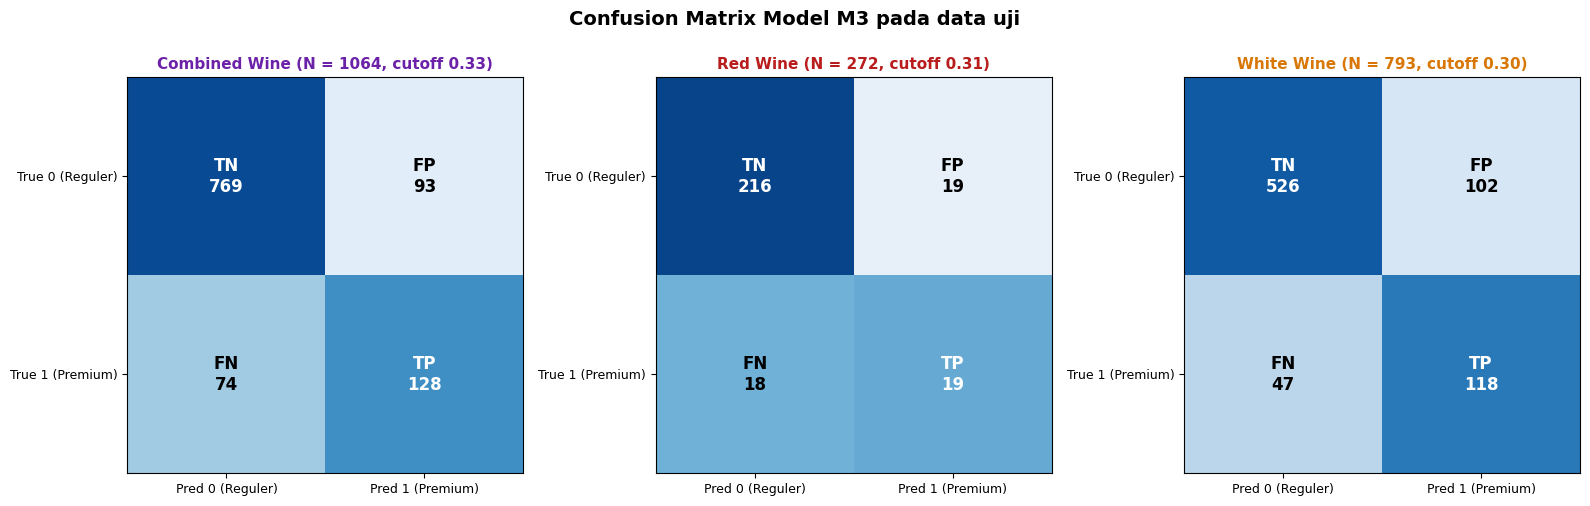

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
cell_labels = [['TN', 'FP'], ['FN', 'TP']]
for ax, s in zip(axes, scopes_list):
    cm = conf_mats[(s, 'M3_ThresholdOpt')]
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
    for r in range(2):
        for c in range(2):
            ax.text(c, r, f'{cell_labels[r][c]}\n{cm[r, c]:,}', ha='center', va='center',
                    fontweight='bold', fontsize=12, color='white' if cm_norm[r, c] > 0.5 else 'black')
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(['Pred 0 (Reguler)', 'Pred 1 (Premium)'], fontsize=9)
    ax.set_yticklabels(['True 0 (Reguler)', 'True 1 (Premium)'], fontsize=9)
    ax.set_title(f'{s} Wine (N = {len(splits[s]["y_test"])}, cutoff {thresholds[s]:.2f})',
                 fontsize=11, fontweight='bold', color=SCOPE_COLORS[s])
fig.suptitle('Confusion Matrix Model M3 pada data uji', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('wine_rf_confusion_matrix.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

## Perbandingan F1 kelas premium antar model

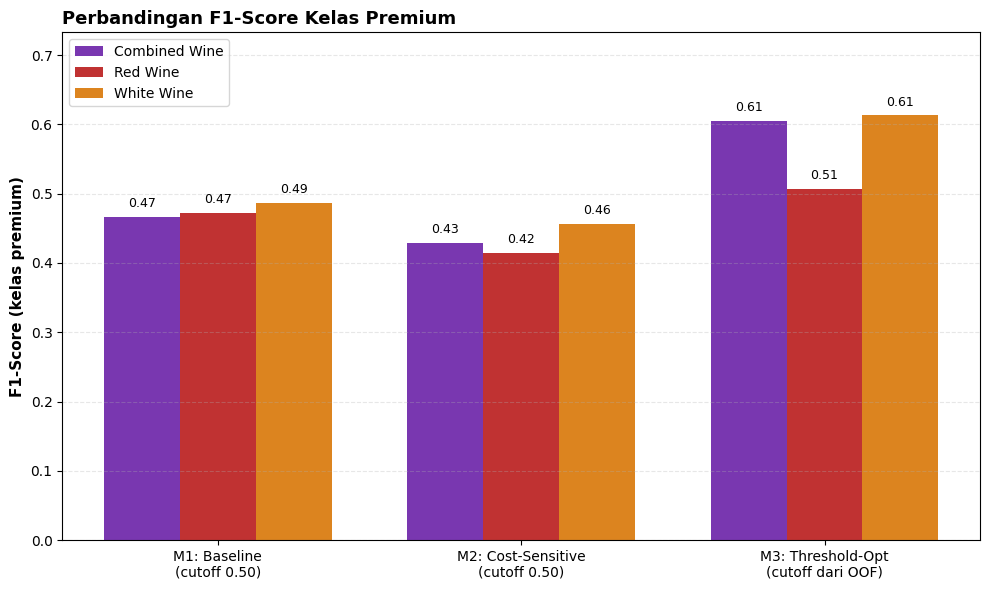

In [30]:
fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(MODEL_NAMES))
width = 0.25
for i, s in enumerate(scopes_list):
    subset = df_metrics[df_metrics['scope'] == s].set_index('model')
    vals = [subset.loc[m, 'f1'] for m in MODEL_NAMES]
    bars = ax.bar(x + (i - 1) * width, vals, width, label=f'{s} Wine', color=SCOPE_COLORS[s], alpha=0.9)
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01, f'{bar.get_height():.2f}',
                ha='center', va='bottom', fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(['M1: Baseline\n(cutoff 0.50)', 'M2: Cost-Sensitive\n(cutoff 0.50)', 'M3: Threshold-Opt\n(cutoff dari OOF)'], fontsize=10)
ax.set_ylabel('F1-Score (kelas premium)', fontsize=11, fontweight='bold')
ax.set_ylim(0, min(1.0, df_metrics['f1'].max() + 0.12))
ax.set_title('Perbandingan F1-Score Kelas Premium', fontsize=13, fontweight='bold', loc='left')
ax.legend(loc='upper left', fontsize=10)
ax.grid(True, axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig('wine_rf_f1_comparison.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()